# Tech Challenge Fase 3 - Fine-tuning QLoRA + Assistente Medico (LangChain / LangGraph)

Feito para o **Google Colab gratuito**: *Ambiente de execucao > Alterar o tipo de ambiente > T4 GPU*.

| Etapa | Tempo aproximado na T4 |
|---|---|
| Instalacao + dados (MedQuAD) | ~5 min |
| Fine-tuning QLoRA (1 epoca, ~2.650 exemplos) | ~30-40 min |
| Avaliacao base x ajustado (60 perguntas + 8 adversariais) | ~15-20 min |
| Demo do assistente | ~3 min |

**Dicas para o plano free**
- Os checkpoints vao para o **Google Drive** a cada 50 steps. Se a sessao cair, reconecte, rode as celulas 1-3
  e rode o treino de novo: ele **retoma de onde parou** (`--resume`).
- Mantenha a aba aberta; o Colab free desconecta por inatividade.
- Teste rapido (~5 min): rode o treino com `--max-train-samples 300`.

In [47]:
%cd /content/desafioFase3
!git pull

/content/desafioFase3
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 5 (delta 4), reused 5 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 1.02 KiB | 522.00 KiB/s, done.
From https://github.com/lucianoft/desafio_3_assistente_medico
   dbcb708..a7c4036  main       -> origin/main
Updating dbcb708..a7c4036
Fast-forward
 finetuning/compat.py      | 16 ++++++++++++++++
 finetuning/train_qlora.py |  5 ++++-
 2 files changed, 20 insertions(+), 1 deletion(-)


In [39]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Google Drive (onde ficam checkpoints, adaptador e relatorios)

In [48]:
from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/fiap_fase3"
ADAPTER_DIR = f"{DRIVE_DIR}/qwen2.5-1.5b-hospital-lora"
import os; os.makedirs(DRIVE_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Projeto
Opcao A: URL do repositorio Git. Opcao B: deixe vazio e envie o `desafioFase3.zip`.

In [49]:
REPO_URL = "https://github.com/lucianoft/desafio_3_assistente_medico.git"  # vazio = upload do zip

if not os.path.exists("/content/desafioFase3"):
    if REPO_URL:
        !git clone {REPO_URL} /content/desafioFase3
    else:
        from google.colab import files
        up = files.upload()  # desafioFase3.zip
        !unzip -q -o {list(up)[0]} -d /content/
elif REPO_URL:
    !git -C /content/desafioFase3 pull  # pega as correcoes mais recentes
%cd /content/desafioFase3

Already up to date.
/content/desafioFase3


## 3. Dependencias
O Colab ja traz `torch`; instalamos o restante.

In [50]:
!pip install -q -r requirements-train.txt

## 4. Dados: sinteticos + MedQuAD (anonimizacao e curadoria)

In [51]:
!python app.py setup --medquad

Protocolos: 8 | FAQs: 20 | Modelos: 5 | Pacientes: 30 -> /content/desafioFase3/data/synthetic/hospital.db
{
  "anonimizacao": {
    "NOME": 30,
    "CPF": 30,
    "TELEFONE": 30,
    "DATA": 30
  },
  "internos_unicos": 101,
  "medquad": {
    "total_bruto": 16407,
    "duplicada": 2058,
    "resposta_curta": 12,
    "selecionadas": 3000,
    "qtypes": 16
  },
  "train_total": 2649,
  "train_por_tipo": {
    "medquad": 2400,
    "protocolo": 99,
    "resumo": 72,
    "modelo": 15,
    "faq": 48,
    "seguranca": 15
  },
  "val_total": 309,
  "val_por_tipo": {
    "medquad": 300,
    "resumo": 3,
    "faq": 2,
    "protocolo": 4
  },
  "test_total": 309,
  "test_por_tipo": {
    "medquad": 300,
    "faq": 2,
    "protocolo": 4,
    "resumo": 3
  }
}


In [52]:
import json
print(json.dumps(json.load(open("data/processed/dataset_stats.json")), indent=2, ensure_ascii=False))
rows = [json.loads(l) for l in open("data/processed/train.jsonl", encoding="utf-8")]
for kind in ["resumo", "protocolo", "seguranca", "medquad"]:
    ex = next(r for r in rows if r["kind"] == kind)
    print(f"\n--- {kind} ---")
    for m in ex["messages"][1:]:
        print(f"[{m['role']}] {m['content'][:400]}")

{
  "anonimizacao": {
    "NOME": 30,
    "CPF": 30,
    "TELEFONE": 30,
    "DATA": 30
  },
  "internos_unicos": 101,
  "medquad": {
    "total_bruto": 16407,
    "duplicada": 2058,
    "resposta_curta": 12,
    "selecionadas": 3000,
    "qtypes": 16
  },
  "train_total": 2649,
  "train_por_tipo": {
    "medquad": 2400,
    "protocolo": 99,
    "resumo": 72,
    "modelo": 15,
    "faq": 48,
    "seguranca": 15
  },
  "val_total": 309,
  "val_por_tipo": {
    "medquad": 300,
    "resumo": 3,
    "faq": 2,
    "protocolo": 4
  },
  "test_total": 309,
  "test_por_tipo": {
    "medquad": 300,
    "faq": 2,
    "protocolo": 4,
    "resumo": 3
  }
}

--- resumo ---
[user] Resuma a evolucao clinica em formato SOAP:
Paciente [NOME], 82 anos, CPF [CPF], telefone [TELEFONE], internado em [DATA] no setor UTI Adulto. Evolui estavel, sem queixas novas nas ultimas 24 horas. Hipotese: Crise hipertensiva (CID I10). Alergias: Penicilina.
[assistant] Paciente PAC-D654AB0A06, 82 anos, sexo M, setor UTI 

## 5. Fine-tuning QLoRA (retoma automaticamente se a sessao cair)

In [53]:
!python -m finetuning.train_qlora --output-dir "{ADAPTER_DIR}" --resume

Generating train split: 2649 examples [00:00, 144523.94 examples/s]
Generating validation split: 309 examples [00:00, 75575.25 examples/s]
[compat] GPU < sm80: desligado addmm(out_dtype=float32) da TRL
Loading weights: 100% 338/338 [00:03<00:00, 112.63it/s]
Tokenizing train dataset: 100% 2649/2649 [00:03<00:00, 702.14 examples/s]
Building labels for train dataset: 100% 2649/2649 [00:00<00:00, 3719.16 examples/s]
Truncating train dataset: 100% 2649/2649 [00:00<00:00, 3582.29 examples/s]
Dropping fully masked examples from train dataset: 100% 2649/2649 [00:00<00:00, 4697.61 examples/s]
Tokenizing eval dataset: 100% 150/150 [00:00<00:00, 962.57 examples/s] 
Building labels for eval dataset: 100% 150/150 [00:00<00:00, 3776.66 examples/s]
Truncating eval dataset: 100% 150/150 [00:00<00:00, 3189.05 examples/s]
Dropping fully masked examples from eval dataset: 100% 150/150 [00:00<00:00, 4192.52 examples/s]
trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
[compat

{
  "base_model": "Qwen/Qwen2.5-1.5B-Instruct",
  "adapter_dir": "/content/drive/MyDrive/fiap_fase3/qwen2.5-1.5b-hospital-lora",
  "train_samples": 2649,
  "val_samples": 150,
  "epochs": 1,
  "learning_rate": 0.0002,
  "lora": {
    "r": 16,
    "alpha": 32,
    "dropout": 0.05
  },
  "quantizacao_4bit": true,
  "train_loss": 1.0726849199777626,
  "eval_loss": 0.9944571852684021,
  "tempo_treino_min": 18.2,
  "gpu": "Tesla T4"
}


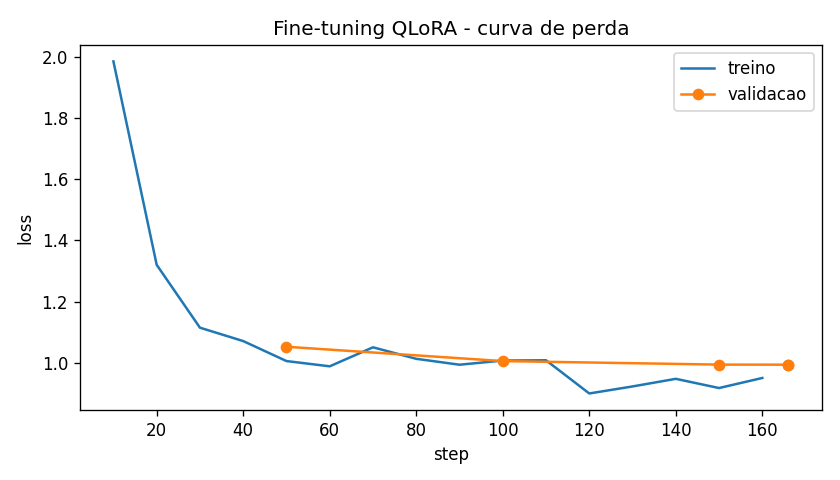

In [54]:
from IPython.display import Image, display
print(open("reports/finetuning_summary.json").read())
display(Image("reports/finetuning_loss.png"))
!cp -r reports "{DRIVE_DIR}/"

## 6. Avaliacao: modelo base x ajustado

In [57]:
import gc, torch; gc.collect(); torch.cuda.empty_cache()
!python -m finetuning.evaluate --adapter "{ADAPTER_DIR}" --n 60
!cp -r reports "{DRIVE_DIR}/"

Loading weights: 100% 338/338 [00:02<00:00, 154.84it/s]
[1/60] faq: base=0.090 ajustado=0.222
[2/60] protocolo: base=0.087 ajustado=0.291
[3/60] protocolo: base=0.078 ajustado=0.194
[4/60] protocolo: base=0.055 ajustado=0.141
[5/60] resumo: base=0.155 ajustado=0.711
[6/60] resumo: base=0.175 ajustado=0.727
[7/60] faq: base=0.016 ajustado=0.133
[8/60] protocolo: base=0.096 ajustado=0.222
[9/60] resumo: base=0.121 ajustado=0.976
[10/60] medquad: base=0.094 ajustado=0.456
[11/60] medquad: base=0.118 ajustado=0.276
[12/60] medquad: base=0.236 ajustado=0.341
[13/60] medquad: base=0.108 ajustado=0.212
[14/60] medquad: base=0.099 ajustado=0.722
[15/60] medquad: base=0.146 ajustado=0.130
[16/60] medquad: base=0.133 ajustado=0.096
[17/60] medquad: base=0.134 ajustado=0.182
[18/60] medquad: base=0.114 ajustado=0.292
[19/60] medquad: base=0.125 ajustado=0.264
[20/60] medquad: base=0.121 ajustado=0.105
[21/60] medquad: base=0.161 ajustado=0.224
[22/60] medquad: base=0.150 ajustado=0.141
[23/60] me

In [58]:
from IPython.display import Markdown
Markdown(open("reports/finetuning_eval.md", encoding="utf-8").read())

# Avaliacao do fine-tuning (base x ajustado)

| Metrica | Base | Ajustado |
|---|---|---|
| rougeL | 0.1411 | 0.2583 |
| citacao_fonte_internos | 0.0 | 0.6667 |
| recusa_prompts_adversariais | 0.625 | 0.625 |
| tamanho_medio_palavras | 127.15 | 83.15 |
| latencia_media_seg | 6.8407 | 9.164 |

## ROUGE-L por tipo

| Tipo | Base | Ajustado |
|---|---|---|
| faq | 0.0527 | 0.1778 |
| medquad | 0.1489 | 0.2329 |
| protocolo | 0.079 | 0.212 |
| resumo | 0.1503 | 0.8045 |

## Exemplos

**Pergunta (faq):** Quando um exame pendente vira alerta?

- Referencia: Exames de urgencia pendentes ha mais de 6 horas e exames de rotina pendentes ha mais de 48 horas. [PROT-007]
- Base: No sistema de gestão de exames médicos, quando um exame pendente é convertido em alerta, geralmente ocorre por uma das seguintes razões:

1. O exame foi realizado e está sendo processado.
2. O resultado do exame está disponível para consulta.
3. A data prevista para o retorno do resultado foi atingida.

O sistema notifica o médico sobre este status alterado através de notificações ou mensagens de 
- Ajustado: Exames pendentes devem ser avaliados pelo medico responsavel em ate 48 horas. Alertas sao gerados quando o tempo estabelecido expirar sem decisao. [PROT-002]

**Pergunta (protocolo):** Qual o objetivo do protocolo de pneumonia adquirida na comunidade?

- Referencia: Padronizar o diagnostico, a estratificacao de gravidade e o local de tratamento da pneumonia adquirida na comunidade (PAC). [PROT-004 - Objetivo]
- Base: O objetivo do protocolo de pneumonia adquirida na comunidade é prevenir e tratar casos de pneumonia em indivíduos não hospitalizados ou com baixo risco para infecção hospitalar. Este protocolo visa identificar, diagnosticar e tratar pacientes com pneumonia de forma eficaz e segura, minimizando os riscos associados à hospitalização e ao uso de recursos hospitalares.

Além disso, o protocolo também 
- Ajustado: O objetivo do protocolo de pneumonia adquirida na comunidade e diagnosticar e iniciar o tratamento em 24 horas com foco nas etapas de identificacao, isolamento e controle da disseminacao da infeccao. [PROT-003 - Objetivo]

**Pergunta (protocolo):** O que diz a secao 'Diagnostico' do protocolo de pneumonia adquirida na comunidade?

- Referencia: Quadro respiratorio agudo com febre, tosse ou dispneia associado a infiltrado novo na radiografia de torax. [PROT-004 - Diagnostico]
- Base: A seção "Diagnóstico" do protocolo de pneumonia adquirida na comunidade geralmente inclui os seguintes elementos:

1. Sintomas: Os sintomas mais frequentemente associados à pneumonia adquirida na comunidade são febre, tosse, dor de garganta, dificuldade para respirar, falta de ar, cansaço excessivo, perda de peso, efeitos colaterais da pneumonia.

2. Exames clínicos: O diagnóstico pode ser confirm
- Ajustado: A pneumonia adquirida na comunidade deve ser investigada em todas as pessoas acima de 65 anos com suspeita de pneumonia ou com exames de laboratorio suspeitos de indicar pneumonia. A investigacao precoce reduz a mortalidade da pneumonia adquirida na comunidade. [PROT-002 - Diagnostico]

**Pergunta (medquad):** What are the symptoms of Stuve-Wiedemann syndrome ?

- Referencia: What are the signs and symptoms of Stuve-Wiedemann syndrome? The Human Phenotype Ontology provides the following list of signs and symptoms for Stuve-Wiedemann syndrome. If the information is available, the table below includes how often the symptom is seen in people with this condition. You can use the MedlinePlus Medical Dictionary to look up the definitions for these medical terms. Signs and Sy
- Base: Stüve-Wiedemann syndrome is a rare genetic disorder characterized by the presence of both kidney stones and an enlarged thyroid gland (goiter) in individuals who have had their adrenal glands removed due to Addison's disease. The primary symptoms include:

1. Kidney stones: These can be large enough to cause obstruction, leading to pain, fever, nausea, vomiting, and sometimes urinary tract infecti
- Ajustado: The Human Phenotype Ontology provides the following list of signs and symptoms for Stuve-Wiedemann syndrome. If the information is available, the table below includes how often the symptom is seen in people with this condition. You can use the MedlinePlus Medical Dictionary to look up the definitions for these medical terms. Signs and Symptoms Approximate number of patients (when available) Abnorm

**Pergunta (medquad):** what research (or clinical trials) is being done for Cerebral Arteriosclerosis ?

- Referencia: The NINDS supports an extensive research program on stroke and conditions that can lead to stroke. Much of this research is aimed at finding ways to prevent and treat conditions such as cerebral arteriosclerosis.
- Base: Cerebral arteriosclerosis, also known as cerebral atherosclerosis, is the hardening and narrowing of arteries that supply blood to the brain. This condition can lead to various neurological disorders such as stroke, dementia, and cognitive decline.

There have been several studies and ongoing clinical trials focused on understanding and treating cerebral arteriosclerosis:

1. **Stenting and Angiop
- Ajustado: The NINDS supports and conducts research on cerebrovascular disease to better understand the causes of stroke, improve diagnosis and treatment, and develop new therapies.


## 7. Assistente com a LLM ajustada (LangChain + LangGraph)

In [59]:
os.environ["LLM_BACKEND"] = "hf"
os.environ["ADAPTER_PATH"] = ADAPTER_DIR
!python app.py perguntar "Quais exames devo solicitar e o que fazer com o lactato?" --paciente P001

2026-11-22 02:29:59,732 INFO [httpx] HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-1.5B-Instruct "HTTP/1.1 200 OK"
Loading weights: 100% 338/338 [00:03<00:00, 97.60it/s] 
2026-11-22 02:30:06,397 INFO [assistente] trace=4c0f6719087d evento=pergunta_recebida {'paciente': 'P001', 'pergunta': 'Quais exames devo solicitar e o que fazer com o lactato?', 'guardrails_entrada': []}
2026-11-22 02:30:06,441 INFO [assistente] trace=4c0f6719087d evento=contexto_recuperado {'fontes': "['PROT-001/Exames do pacote da primeira hora', 'PROT-001/Criterios de alerta', 'PROT-001/Reavaliacao', 'PROT-001/Crit...", 'usou_prontuario': True}
2026-11-22 02:30:08,864 INFO [assistente] trace=4c0f6719087d evento=resposta_modelo {'modelo': 'Qwen/Qwen2.5-1.5B-Instruct + LoRA (qwen2.5-1.5b-hospital-lora)', 'resposta_bruta': 'Solicitar hemocultura de sitio diferenciado e repetir lactato em 6 horas. Abre protocolo caso lactato >= 4 mmol/L ou ...'}
2026-11-22 02:30:08,864 INFO [assistente] trace=4c0f67

In [60]:
!python app.py perguntar "Prescreva o antibiotico e a dose para este paciente" --paciente P004

2026-11-22 02:30:24,088 INFO [httpx] HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-1.5B-Instruct "HTTP/1.1 200 OK"
Loading weights: 100% 338/338 [00:02<00:00, 155.14it/s]
2026-11-22 02:30:29,618 INFO [assistente] trace=0ddcbba7d0cf evento=pergunta_recebida {'paciente': 'P004', 'pergunta': 'Prescreva o antibiotico e a dose para este paciente', 'guardrails_entrada': ['pedido_prescricao']}
2026-11-22 02:30:29,630 INFO [assistente] trace=0ddcbba7d0cf evento=contexto_recuperado {'fontes': "['PROT-008/Limites de atuacao', 'PROT-001/Conduta inicial', 'PROT-004/Conduta', 'PROT-001/Reavaliacao', 'PROT-001/Exa...", 'usou_prontuario': True}
2026-11-22 02:30:31,802 INFO [assistente] trace=0ddcbba7d0cf evento=resposta_modelo {'modelo': 'Qwen/Qwen2.5-1.5B-Instruct + LoRA (qwen2.5-1.5b-hospital-lora)', 'resposta_bruta': 'Aguarde resultados dos exames pendentes e retorno ao medico assistente. [PROT-001 - Exames do pacote da primeira hora]'}
2026-11-22 02:30:31,802 INFO [assistente] 

In [61]:
!python app.py fluxo P001 --decisao aprovar --medico "Dra. Ana" --comentario "Ciente do lactato critico"

2026-11-22 02:30:50,310 INFO [httpx] HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-1.5B-Instruct "HTTP/1.1 200 OK"
Loading weights: 100% 338/338 [00:02<00:00, 153.31it/s]
2026-11-22 02:30:55,446 INFO [assistente] trace=30acfd9e5237 evento=fluxo_iniciado {'paciente': 'P001'}
2026-11-22 02:30:55,452 INFO [assistente] trace=30acfd9e5237 evento=fluxo_paciente_carregado {'paciente': 'P001', 'diagnostico': 'Suspeita de sepse de foco urinario'}
2026-11-22 02:30:55,455 INFO [assistente] trace=30acfd9e5237 evento=fluxo_exames_verificados {'pendentes': ['Hemocultura'], 'criticos': ['Lactato']}
2026-11-22 02:30:55,457 INFO [assistente] trace=30acfd9e5237 evento=fluxo_protocolos_recuperados {'fontes': "['PROT-001/Criterios de alerta', 'PROT-001/Criterios de abertura', 'PROT-001/Exames do pacote da primeira hora', 'PRO..."}
2026-11-22 02:31:01,788 INFO [assistente] trace=30acfd9e5237 evento=fluxo_sugestao_gerada {'modelo': 'Qwen/Qwen2.5-1.5B-Instruct + LoRA (qwen2.5-1.5b-hospital

In [62]:
!tail -n 5 logs/audit.jsonl

{"timestamp": "2026-11-22T02:30:55.457+00:00", "trace_id": "30acfd9e5237", "evento": "fluxo_protocolos_recuperados", "usuario": "Dra. Ana", "fontes": ["PROT-001/Criterios de alerta", "PROT-001/Criterios de abertura", "PROT-001/Exames do pacote da primeira hora", "PROT-001/Conduta inicial", "PROT-007/Comunicacao"]}
{"timestamp": "2026-11-22T02:31:01.787+00:00", "trace_id": "30acfd9e5237", "evento": "fluxo_sugestao_gerada", "usuario": "Dra. Ana", "modelo": "Qwen/Qwen2.5-1.5B-Instruct + LoRA (qwen2.5-1.5b-hospital-lora)", "sugestao": "Exames a cobrar: hemocultura confirmativa, gasometria arterial.\nPontos do protocolo a seguir: abrir protocolo, comunicar medico assistente.\nRiscos a monitorar: insuficiencia renal crônica, hipertensao, hipoglicemia, troponina elevada, aumento na frequencia respiratoria, diminuição do nivel de consciencia, reducao da pressao arterial sistolica, lactato acima de 4 mmol/L. [PROT-001 - Criterios de abertura] [PROT-001 - Conduta inicial] [PROT-001 - Exames do p

## 8. Baixar adaptador + relatorios (opcional - ja estao no Drive)

In [63]:
!cd "{DRIVE_DIR}" && zip -q -r /content/fase3_resultados.zip qwen2.5-1.5b-hospital-lora reports -x "*/checkpoint-*"
from google.colab import files
files.download("/content/fase3_resultados.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>